# Missing data at inference time
Simulates outages in the test period and compares ways of handling them (Section 3.2 of the report).
Whole (location, day) blocks of features are removed, like a late meter delivery or a failed weather request.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import xgboost as xgb
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer

from forecast_checks import MakeTrainingData
from imputation import (LAG_COLS, WEATHER_COLS, BASELINE_COL, AvailabilityModels, ColumnImputer, FallbackForecaster,
                        MissingValueHandler, MultipleImputationForecaster, OutageAugmenter, OutageSimulator,
                        add_missing_indicators)

warnings.filterwarnings("ignore", category=UserWarning, module="sklearn")
warnings.filterwarnings("ignore", category=Warning, module="sklearn.impute")

In [2]:
OUTAGE_SHARE = 0.2   #share of (location, day) pairs hit by an outage
SEED = 0
MODEL_PARAMS = dict(enable_categorical=True, tree_method="hist", random_state=42,
                    n_estimators=500, learning_rate=0.05, max_depth=5)
SCENARIOS = {
    "Lag 7 d missing": ["consumption_7days_ago"],
    "Last available day missing": ["consumption_6days_ago", "min_consumption_last_available_day",
                                   "max_consumption_last_available_day"],
    "All consumption features missing": LAG_COLS,
    "Whole weather forecast missing": WEATHER_COLS,
}

In [3]:
trainer = MakeTrainingData()
data = trainer.get_train_test()
X_train, y_train = data["train"]["feature"], data["train"]["target"]
X_test, y_test = data["test"]["feature"], data["test"]["target"]

In [4]:
#Score on the same hours as the other notebooks: drop test rows where a consumption lag is missing in the raw data
scored = X_test.filter(like="consumption").notna().all(axis=1)
X_test, y_test = X_test[scored], y_test[scored]
test_dates = trainer.df.loc[X_test.index, "date"]

In [5]:
def make_model():
    return xgb.XGBRegressor(**MODEL_PARAMS)


model = make_model().fit(X_train, y_train)
handler = MissingValueHandler().fit(X_train, y_train)
simulator = OutageSimulator(share=OUTAGE_SHARE, seed=SEED)

## Methods
- **Native NaN / mean / KNN:** the usual quick fixes, with the model trained on complete data.
- **MICE (BayesianRidge, ExtraTrees), multiple imputation:** chained-equation imputation of the lag features; multiple imputation averages the forecasts from five draws.
- **MICE + fallback:** the protocol in the report. With a *no-lag model* as last resort when all consumption features are missing.
- **Trained with outages:** the model is trained on the training data plus copies where the scenarios' columns are removed, and handles NaN natively. A variant also gets missing-value indicators.
- **One model per pattern:** a separate model for each pattern of missing features, so nothing is imputed.
- **Mean of available lags:** the average of the lag 6, 7 and 14 values that exist.

In [6]:
train_dates = trainer.df.loc[X_train.index, "date"]
X_aug, y_aug = OutageAugmenter(SCENARIOS).augment(X_train, y_train, train_dates)

In [7]:
always_mice = FallbackForecaster(model, MissingValueHandler(max_missing_lag_share=1.0).fit(X_train, y_train))
proposed = FallbackForecaster(model, handler)
mean_imputer = ColumnImputer().fit(X_train)
knn_imputer = ColumnImputer(KNNImputer(n_neighbors=5)).fit(X_train)
trees = IterativeImputer(estimator=ExtraTreesRegressor(n_estimators=30, max_depth=12, n_jobs=-1, random_state=0),
                         max_iter=5, random_state=0)
mice_trees = FallbackForecaster(model, MissingValueHandler(max_missing_lag_share=1.0, lag_imputer=trees)
                                .fit(X_train, y_train))
multiple = MultipleImputationForecaster(model, handler).fit(X_train)
by_pattern = AvailabilityModels(make_model, handler).fit(X_train, y_train)
proposed_v2 = FallbackForecaster(model, handler, last_resort=by_pattern)
model_aug = make_model().fit(X_aug, y_aug)
model_aug_indicators = make_model().fit(add_missing_indicators(X_aug), y_aug)

In [8]:
def baseline_forecast(X):
    #Same hour last week, and the profile where that lag is missing too
    return X[BASELINE_COL].fillna(handler.profile(X))


def mean_of_lags(X):
    lags = X[["consumption_6days_ago", "consumption_7days_ago", "consumption_14days_ago"]].mean(axis=1)
    return lags.fillna(handler.profile(X))


STRATEGIES = {
    "XGBoost, NaN handled natively": lambda X: pd.Series(model.predict(X), index=X.index),
    "Mean imputation": lambda X: pd.Series(model.predict(mean_imputer.transform(X)), index=X.index),
    "KNN imputation (k=5)": lambda X: pd.Series(model.predict(knn_imputer.transform(X)), index=X.index),
    "MICE": always_mice.predict,
    "MICE, ExtraTrees": mice_trees.predict,
    "Multiple imputation (m=5)": multiple.predict,
    "MICE + fallback (report)": proposed.predict,
    "MICE + fallback, no-lag model": proposed_v2.predict,
    "Trained with outages": lambda X: pd.Series(model_aug.predict(X), index=X.index),
    "Trained with outages + indicators": lambda X: pd.Series(
        model_aug_indicators.predict(add_missing_indicators(X)), index=X.index),
    "One model per pattern": by_pattern.predict,
    "Mean of available lags": mean_of_lags,
    "Baseline (same hour last week)": baseline_forecast,
}


def mae_on(rows, forecast):
    return (forecast[rows] - y_test[rows]).abs().mean()

## Scenarios
MAE [MW] on the hours that fall on an outage day (the other hours are unaffected).

In [9]:
hit_rows = simulator.hit(X_test, test_dates)
scenario_mae = {}
for scenario, columns in SCENARIOS.items():
    X_missing = simulator.apply(X_test, test_dates, columns)
    scenario_mae[scenario] = {name: mae_on(hit_rows, predict(X_missing)) for name, predict in STRATEGIES.items()}
results = pd.DataFrame(scenario_mae).T
results.insert(0, "No outage (report)", mae_on(hit_rows, proposed.predict(X_test)))
results.round(3).T

,Lag 7 d missing,Last available day missing,All consumption features missing,Whole weather forecast missing
No outage (report),0.379,0.379,0.379,0.379
"XGBoost, NaN handled natively",0.701,2.773,3.916,0.615
Mean imputation,0.404,2.563,3.054,0.635
KNN imputation (k=5),0.394,0.571,2.574,0.688
MICE,0.384,0.398,2.986,0.441
"MICE, ExtraTrees",0.384,0.372,2.921,0.441
Multiple imputation (m=5),0.385,0.397,2.944,0.441
MICE + fallback (report),0.384,0.398,2.788,0.441
"MICE + fallback, no-lag model",0.384,0.398,0.888,0.441
Trained with outages,0.432,0.397,1.671,0.575


## Threshold for falling back
`k` of the five lag features are removed at random on the outage days. MICE + model is compared with one model per
pattern and with the model that does not use consumption at all. The threshold `max_missing_lag_share` should be the
largest k/5 for which MICE is still better than the weather and calendar model.

In [10]:
no_lag_features = by_pattern.features_["weather and calendar only"]
no_lag_model = by_pattern.models_["weather and calendar only"]


def predict_without_lags(X):
    return pd.Series(no_lag_model.predict(handler.impute_weather(X)[no_lag_features]), index=X.index)


threshold_mae = {}
for k in range(1, len(LAG_COLS) + 1):
    X_missing = simulator.apply_random_subset(X_test, test_dates, LAG_COLS, k)
    threshold_mae[k] = {"MICE + model": mae_on(hit_rows, always_mice.predict(X_missing)),
                        "One model per pattern": mae_on(hit_rows, by_pattern.predict(X_missing)),
                        "Weather and calendar model": mae_on(hit_rows, predict_without_lags(X_missing))}
threshold = pd.DataFrame(threshold_mae).T.rename_axis("missing lag features")
threshold.round(3)

,MICE + model,One model per pattern,Weather and calendar model
missing lag features,,,
1,0.383,0.487,0.888
2,0.392,0.744,0.888
3,0.393,0.836,0.888
4,0.405,0.888,0.888
5,2.986,0.888,0.888


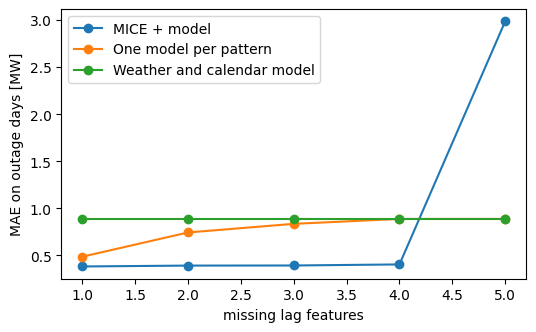

In [11]:
threshold.plot(marker="o", figsize=(6, 3.5), ylabel="MAE on outage days [MW]")
plt.show()

In [12]:
RESULTS = {"outage_share": OUTAGE_SHARE, "seed": SEED,
           "scenarios": results.round(4).to_dict(orient="index"),
           "threshold": threshold.round(4).to_dict(orient="index")}
with open("results/imputation.json", "w") as f:
    json.dump(RESULTS, f, indent=2)